# Detección de exoplanetas con IA
## Cierre de la fase 2 y fase 3 de CRISP-ML(Q): ingeniería del modelo

| Fase | Fecha | Contenido |
|---|---|---|
| 2. Preparación de datos (cierre) | 12 – 13 nov | Validación de los parámetros del preprocesamiento |
| 3. Ingeniería del modelo | 14 – 17 nov | Regresión logística, Random Forest, XGBoost y CNN 1D con validación cruzada |

**Regla de esta fase:** `exoTest.csv` **no se usa**. Todas las comparaciones se hacen con validación cruzada sobre el entrenamiento. El conjunto de prueba se reserva para la fase 4, así la evaluación final es honesta.

## Configuración

In [1]:
import os, sys, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
SEED = 42
np.random.seed(SEED)

# Código del proyecto (src/). En Colab se clona el repositorio.
if not os.path.exists('src/preprocesamiento.py') and not os.path.exists('../src/preprocesamiento.py'):
    os.system('git clone -q https://github.com/gabiamer/exoplanetas-ia.git')
    os.chdir('exoplanetas-ia')
RAIZ = '..' if os.path.exists('../src/preprocesamiento.py') else '.'
sys.path.insert(0, os.path.join(RAIZ, 'src'))
from preprocesamiento import limpiar_curvas, espectro_fourier, recodificar_etiqueta

# Datos
DATA_DIR = os.environ.get('KEPLER_DIR')
if DATA_DIR is None:
    import kagglehub
    DATA_DIR = kagglehub.dataset_download('keplersmachines/kepler-labelled-time-series-data')
train = pd.read_csv(os.path.join(DATA_DIR, 'exoTrain.csv'))
X_crudo = train.drop(columns='LABEL').values
y = recodificar_etiqueta(train['LABEL'])
print('Entrenamiento:', X_crudo.shape, '| con planeta:', y.sum())

Entrenamiento: (5087, 3197) | con planeta: 37


## Validación cruzada y métricas

- **Validación cruzada estratificada de 5 pliegues, con mezcla:** cada pliegue tiene unas 7 estrellas con planeta. Recuerda que en el archivo están todas al inicio.
- **SMOTE va dentro de cada pliegue** (`imblearn.Pipeline`): las estrellas sintéticas se crean solo con los datos de entrenamiento del pliegue, nunca con los de validación.
- **Métrica principal: AP (área bajo la curva precisión-recall).** Mide qué tan bien ordena el modelo las estrellas por probabilidad de tener planeta, sin depender de un umbral. Con clases tan desbalanceadas es más informativa que el accuracy o el ROC-AUC.
- También se reportan recall, precisión y F1 con el umbral por defecto (0,5) y con el **mejor umbral encontrado en validación**. El umbral definitivo se fija en la fase 4.

In [2]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             recall_score, precision_score, f1_score)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
PLIEGUES = list(cv.split(X_crudo, y))

def resumen(nombre, y_true, prob):
    p05 = (prob >= 0.5).astype(int)
    prec, rec, umb = precision_recall_curve(y_true, prob)
    f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
    k = int(np.argmax(f1s))
    return {'Modelo': nombre,
            'AP': average_precision_score(y_true, prob),
            'Recall (0,5)': recall_score(y_true, p05),
            'Precisión (0,5)': precision_score(y_true, p05, zero_division=0),
            'F1 (0,5)': f1_score(y_true, p05),
            'Mejor umbral': umb[k],
            'Recall (mejor)': rec[k], 'Precisión (mejor)': prec[k], 'F1 (mejor)': f1s[k]}

def validar(modelo_factory, X, y):
    """Devuelve probabilidades fuera de pliegue (cada estrella predicha por un modelo que no la vio)
    y el AP medio en entrenamiento, para detectar sobreajuste."""
    oof = np.zeros(len(y)); ap_train = []
    for tr, va in PLIEGUES:
        m = modelo_factory()
        m.fit(X[tr], y[tr])
        oof[va] = m.predict_proba(X[va])[:, 1]
        ap_train.append(average_precision_score(y[tr], m.predict_proba(X[tr])[:, 1]))
    return oof, float(np.mean(ap_train))

# Cierre de la fase 2: validar los parámetros del preprocesamiento

En la fase 2 se eligieron una ventana de 101 puntos para quitar la tendencia y σ = 2 para suavizar. Aquí se comprueba con validación cruzada que **limpiar ayuda** y qué parámetros funcionan mejor. Se usa un Random Forest sobre el espectro de Fourier como modelo de referencia.

In [3]:
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

def rf_ref():
    return Pipeline([('smote', SMOTE(random_state=SEED)),
                     ('rf', RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED))])

variantes = {'Sin limpieza (solo normalizar)': None,
             'Ventana 51, σ = 2': (51, 2), 'Ventana 101, σ = 2': (101, 2), 'Ventana 201, σ = 2': (201, 2),
             'Ventana 101, σ = 1': (101, 1), 'Ventana 101, σ = 4': (101, 4)}
filas = []
for nombre, params in variantes.items():
    t0 = time.time()
    if params is None:
        Z = (X_crudo - X_crudo.mean(1, keepdims=True)) / X_crudo.std(1, keepdims=True)
    else:
        Z = limpiar_curvas(X_crudo, ventana=params[0], sigma=params[1])
    oof, _ = validar(rf_ref, espectro_fourier(Z), y)
    filas.append({'Preprocesamiento': nombre, 'AP (validación cruzada)': average_precision_score(y, oof)})
    print(f'{nombre:32s} AP = {filas[-1]["AP (validación cruzada)"]:.3f}  ({time.time() - t0:.0f} s)')
tabla_params = pd.DataFrame(filas).set_index('Preprocesamiento').round(3)
tabla_params

Sin limpieza (solo normalizar)   AP = 0.439  (179 s)


Ventana 51, σ = 2                AP = 0.599  (160 s)


Ventana 101, σ = 2               AP = 0.623  (163 s)


Ventana 201, σ = 2               AP = 0.635  (185 s)


Ventana 101, σ = 1               AP = 0.649  (161 s)


Ventana 101, σ = 4               AP = 0.562  (171 s)


,AP (validación cruzada)
Preprocesamiento,
Sin limpieza (solo normalizar),0.439
"Ventana 51, σ = 2",0.599
"Ventana 101, σ = 2",0.623
"Ventana 201, σ = 2",0.635
"Ventana 101, σ = 1",0.649
"Ventana 101, σ = 4",0.562


In [4]:
mejor_param = tabla_params['AP (validación cruzada)'].idxmax()
print('Mejor configuración:', mejor_param)

Mejor configuración: Ventana 101, σ = 1


**Conclusión (control de calidad de la fase 2):**
- La limpieza **mejora claramente** el resultado: el AP sube de 0,44 (solo normalizar) a 0,60 – 0,65 con el pipeline. Esto confirma que la fase 2 aporta.
- Entre las variantes las diferencias son pequeñas. σ = 1 sale un poco mejor (0,65 frente a 0,62 de la configuración actual), pero con solo 37 estrellas positivas una diferencia así puede ser ruido. Se mantiene ventana 101 y σ = 2 para comparar los modelos, y σ = 1 se vuelve a probar en el ajuste de hiperparámetros del 17 de noviembre.

**Fase 2 cerrada.**

# Fase 3 — Ingeniería del modelo (14 – 17 nov)

Se entrenan cuatro modelos, de menor a mayor complejidad:

| Modelo | Entrada | Manejo del desbalance |
|---|---|---|
| Regresión logística (modelo base) | Espectro de Fourier (1.598 valores) | SMOTE dentro del pliegue |
| Random Forest | Espectro de Fourier | SMOTE dentro del pliegue |
| XGBoost | Espectro de Fourier | Peso de la clase positiva (`scale_pos_weight`) |
| CNN 1D (Deep Learning) | Curva limpia (3.197 valores) | Peso en la función de pérdida + sobremuestreo por lote |

In [5]:
Z = limpiar_curvas(X_crudo)          # parámetros por defecto del módulo (ventana 101, σ = 2)
F = espectro_fourier(Z)
resultados, oofs, ap_train = [], {}, {}

## Modelo 1: Regresión logística (modelo base)

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

def lr():
    return Pipeline([('escala', StandardScaler()), ('smote', SMOTE(random_state=SEED)),
                     ('lr', LogisticRegression(C=0.01, max_iter=3000))])
t0 = time.time()
oofs['Regresión logística'], ap_train['Regresión logística'] = validar(lr, F, y)
resultados.append(resumen('Regresión logística', y, oofs['Regresión logística']))
print(f'{time.time() - t0:.0f} s'); pd.DataFrame(resultados[-1:]).round(3)

2 s


,Modelo,AP,"Recall (0,5)","Precisión (0,5)","F1 (0,5)",Mejor umbral,Recall (mejor),Precisión (mejor),F1 (mejor)
0,Regresión logística,0.57,0.649,0.686,0.667,0.759,0.595,0.786,0.677


## Modelo 2: Random Forest

In [7]:
def rf():
    return Pipeline([('smote', SMOTE(random_state=SEED)),
                     ('rf', RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=SEED))])
t0 = time.time()
oofs['Random Forest'], ap_train['Random Forest'] = validar(rf, F, y)
resultados.append(resumen('Random Forest', y, oofs['Random Forest']))
print(f'{time.time() - t0:.0f} s'); pd.DataFrame(resultados[-1:]).round(3)

244 s


,Modelo,AP,"Recall (0,5)","Precisión (0,5)","F1 (0,5)",Mejor umbral,Recall (mejor),Precisión (mejor),F1 (mejor)
0,Random Forest,0.623,0.054,1.0,0.103,0.196,0.541,0.87,0.667


## Modelo 3: XGBoost

In [8]:
from xgboost import XGBClassifier
peso = (y == 0).sum() / (y == 1).sum()   # unas 136 estrellas sin planeta por cada una con planeta

def xgb():
    return XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8,
                         colsample_bytree=0.3, scale_pos_weight=peso, eval_metric='aucpr',
                         n_jobs=-1, random_state=SEED)
t0 = time.time()
oofs['XGBoost'], ap_train['XGBoost'] = validar(xgb, F, y)
resultados.append(resumen('XGBoost', y, oofs['XGBoost']))
print(f'{time.time() - t0:.0f} s'); pd.DataFrame(resultados[-1:]).round(3)

113 s


,Modelo,AP,"Recall (0,5)","Precisión (0,5)","F1 (0,5)",Mejor umbral,Recall (mejor),Precisión (mejor),F1 (mejor)
0,XGBoost,0.704,0.405,1.0,0.577,0.046,0.622,0.767,0.687


## Modelo 4: Red neuronal convolucional 1D

La CNN recibe la **curva limpia completa** y aprende sola qué patrones buscar. No usa Fourier.

- **4 bloques convolucionales** (convolución → normalización por lotes → ReLU → max pooling). Los filtros detectan formas locales como una caída de brillo, y el pooling reduce la longitud de 3.197 a 12.
- **Max pooling global:** se queda con la respuesta más fuerte de cada filtro en toda la curva, sin importar dónde ocurre el tránsito.
- **Dropout (0,3) + una neurona de salida con sigmoide:** da la probabilidad de que la estrella tenga planeta.
- **Pérdida:** *binary cross-entropy*. Cada lote se arma con un 25 % de estrellas con planeta (sobremuestreo), para que la red las vea seguido.
- **Aumento de datos:** cada curva se desplaza en el tiempo al azar y a veces se invierte. Un tránsito sigue siendo un tránsito, y así la red no memoriza las 30 estrellas positivas de cada pliegue.

In [9]:
import torch, torch.nn as nn
torch.manual_seed(SEED)
torch.set_num_threads(os.cpu_count() or 2)

class CNN1D(nn.Module):
    def __init__(self):
        super().__init__()
        def bloque(entrada, salida, k):
            return nn.Sequential(nn.Conv1d(entrada, salida, k, padding=k // 2), nn.BatchNorm1d(salida),
                                 nn.ReLU(), nn.MaxPool1d(4))
        self.features = nn.Sequential(bloque(1, 16, 11), bloque(16, 32, 11), bloque(32, 64, 7), bloque(64, 64, 5))
        self.salida = nn.Sequential(nn.AdaptiveMaxPool1d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(64, 1))
    def forward(self, x):
        return self.salida(self.features(x)).squeeze(1)   # logit; la sigmoide se aplica al predecir

class ClasificadorCNN:
    """Envoltura con fit / predict_proba, para usarla igual que los modelos de scikit-learn."""
    def __init__(self, epocas=25, lote=64, frac_pos=0.25, lr=1e-3):
        self.epocas, self.lote, self.frac_pos, self.lr = epocas, lote, frac_pos, lr
    def _aumentar(self, xb):
        desplaz = np.random.randint(0, xb.shape[-1])
        xb = torch.roll(xb, desplaz, dims=-1)
        return torch.flip(xb, dims=[-1]) if np.random.rand() < 0.5 else xb
    def fit(self, X, y):
        rng = np.random.default_rng(SEED)
        self.red = CNN1D(); opt = torch.optim.Adam(self.red.parameters(), lr=self.lr, weight_decay=1e-4)
        X = torch.tensor(X[:, None, :], dtype=torch.float32)
        pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
        n_pos = int(self.lote * self.frac_pos)
        self.perdidas = []
        for _ in range(self.epocas):
            self.red.train(); total = 0
            for _ in range(len(y) // self.lote):
                idx = np.concatenate([rng.choice(pos, n_pos), rng.choice(neg, self.lote - n_pos)])
                xb = self._aumentar(X[idx]); yb = torch.tensor(y[idx], dtype=torch.float32)
                opt.zero_grad()
                perdida = nn.functional.binary_cross_entropy_with_logits(self.red(xb), yb)
                perdida.backward(); opt.step(); total += perdida.item()
            self.perdidas.append(total / (len(y) // self.lote))
        return self
    def predict_proba(self, X):
        self.red.eval()
        with torch.no_grad():
            p = torch.cat([torch.sigmoid(self.red(torch.tensor(X[i:i + 512, None, :], dtype=torch.float32)))
                           for i in range(0, len(X), 512)]).numpy()
        return np.column_stack([1 - p, p])

t0 = time.time()
oofs['CNN 1D'], ap_train['CNN 1D'] = validar(lambda: ClasificadorCNN(), Z, y)
resultados.append(resumen('CNN 1D', y, oofs['CNN 1D']))
print(f'{time.time() - t0:.0f} s'); pd.DataFrame(resultados[-1:]).round(3)

491 s


,Modelo,AP,"Recall (0,5)","Precisión (0,5)","F1 (0,5)",Mejor umbral,Recall (mejor),Precisión (mejor),F1 (mejor)
0,CNN 1D,0.347,0.405,0.536,0.462,0.564,0.405,0.536,0.462


# Comparación de modelos

In [10]:
tabla = pd.DataFrame(resultados).set_index('Modelo')
tabla.insert(0, 'AP entrenamiento', pd.Series(ap_train))
tabla = tabla.sort_values('AP', ascending=False)
tabla.round(3)

,AP entrenamiento,AP,"Recall (0,5)","Precisión (0,5)","F1 (0,5)",Mejor umbral,Recall (mejor),Precisión (mejor),F1 (mejor)
Modelo,,,,,,,,,
XGBoost,1.00,0.704,0.405,1.000,0.577,0.046,0.622,0.767,0.687
Random Forest,1.00,0.623,0.054,1.000,0.103,0.196,0.541,0.870,0.667
Regresión logística,1.00,0.570,0.649,0.686,0.667,0.759,0.595,0.786,0.677
CNN 1D,0.97,0.347,0.405,0.536,0.462,0.564,0.405,0.536,0.462


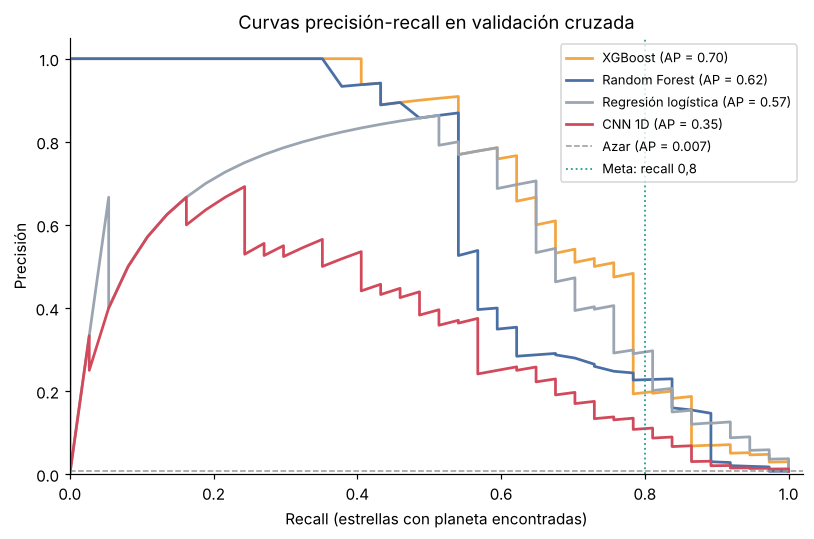

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 5))
colores = {'Regresión logística': '#9aa5b1', 'Random Forest': '#4a6fa5', 'XGBoost': '#f2a541', 'CNN 1D': '#d1495b'}
for nombre in tabla.index:
    prec, rec, _ = precision_recall_curve(y, oofs[nombre])
    ax.plot(rec, prec, lw=1.8, color=colores[nombre], label=f'{nombre} (AP = {tabla.loc[nombre, "AP"]:.2f})')
ax.axhline(y.mean(), ls='--', color='#999', lw=1, label=f'Azar (AP = {y.mean():.3f})')
ax.axvline(0.8, ls=':', color='#2a9d8f', lw=1.2, label='Meta: recall 0,8')
ax.set_xlabel('Recall (estrellas con planeta encontradas)'); ax.set_ylabel('Precisión')
ax.set_title('Curvas precisión-recall en validación cruzada'); ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.05)
ax.legend(loc='upper right', fontsize=8.5); plt.tight_layout(); plt.show()

## Control de calidad de la fase 3

In [12]:
base = tabla.loc['Regresión logística', 'AP']

def cumple_criterios(prob):
    """¿Existe un umbral con recall ≥ 0,8 y F1 ≥ 0,6 en validación?"""
    prec, rec, _ = precision_recall_curve(y, prob)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    return bool(((rec >= 0.8) & (f1 >= 0.6)).any())

qa = pd.DataFrame({
    'Supera al modelo base (AP)': tabla['AP'] > base,
    'Brecha entrenamiento - validación (AP)': (tabla['AP entrenamiento'] - tabla['AP']).round(3),
    'Alcanza recall ≥ 0,8 y F1 ≥ 0,6 con algún umbral': [cumple_criterios(oofs[n]) for n in tabla.index],
}, index=tabla.index)
qa

,Supera al modelo base (AP),Brecha entrenamiento - validación (AP),"Alcanza recall ≥ 0,8 y F1 ≥ 0,6 con algún umbral"
Modelo,,,
XGBoost,True,0.296,False
Random Forest,True,0.377,False
Regresión logística,False,0.430,False
CNN 1D,False,0.622,False


In [13]:
os.makedirs(os.path.join(RAIZ, 'docs'), exist_ok=True)
tabla.round(4).to_csv(os.path.join(RAIZ, 'docs', 'resultados_fase3_cv.csv'))
np.savez_compressed('oof_fase3.npz', y=y, **{k.replace(' ', '_'): v for k, v in oofs.items()})
print('Guardado: docs/resultados_fase3_cv.csv y oof_fase3.npz')

Guardado: docs/resultados_fase3_cv.csv y oof_fase3.npz


## Conclusiones de la fase 3 (avance al 16 de noviembre)

| Modelo | AP | Mejor F1 en validación | Recall / precisión con ese umbral |
|---|---|---|---|
| **XGBoost** | **0,70** | **0,69** | 0,62 / 0,77 |
| Random Forest | 0,62 | 0,67 | 0,54 / 0,87 |
| Regresión logística (base) | 0,57 | 0,68 | 0,59 / 0,79 |
| CNN 1D | 0,35 | 0,46 | 0,41 / 0,54 |

- **XGBoost es el mejor modelo hasta ahora:** tiene el AP más alto, 0,70 frente a 0,57 del modelo base. Es el candidato principal para la fase 4.
- **El umbral de 0,5 no sirve para todos los modelos.** Por ejemplo, Random Forest con 0,5 solo encuentra el 5 % de los planetas, pero con su mejor umbral llega a F1 0,67. Sus probabilidades son bajas por el desbalance. Por eso el umbral se ajusta en la fase 4.
- **La CNN 1D es la más débil:** llega a AP 0,97 en entrenamiento pero solo 0,35 en validación, o sea que **memoriza**. Con unas 30 estrellas con planeta por pliegue, el Deep Learning no tiene suficientes ejemplos positivos para generalizar. Los modelos sobre el espectro de Fourier aprovechan mejor tan pocos datos.
- **Sobreajuste:** todos los modelos llegan a un AP de 1 o casi 1 en entrenamiento. Con tan pocos positivos es esperable, y se controlará con regularización al ajustar los hiperparámetros.
- **Criterios de éxito: todavía no se cumplen.** Ningún modelo logra a la vez recall ≥ 0,8 y F1 ≥ 0,6 en validación. Si se baja el umbral hasta recall 0,8, la precisión cae al 20 – 30 % (F1 de 0,32 a 0,44).

**Pendiente para el 17 de noviembre (ajuste de hiperparámetros):**
1. XGBoost: búsqueda de profundidad, número de árboles, tasa de aprendizaje y fracción de columnas, más regularización.
2. Volver a probar σ = 1 en el preprocesamiento con el mejor modelo.
3. CNN 1D: más regularización (dropout, menos filtros) o entrenarla sobre el espectro de Fourier.
4. Si tras el ajuste no se alcanza el criterio, en la fase 4 se decide **entre priorizar recall** (más falsas alarmas) **o revisar el criterio**. Esta iteración está prevista en CRISP-ML(Q): si una fase no pasa su control de calidad, se vuelve a la anterior.